In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('talk')

project_root = Path.cwd().resolve()
feature_path = None
for candidate in [project_root, project_root.parent]:
    p = candidate / 'data' / 'processed' / 'features.csv'
    if p.exists():
        feature_path = p
        break
if feature_path is None:
    raise FileNotFoundError('Could not find data/processed/features.csv in the current workspace.')

df = pd.read_csv(feature_path)
print(f'Loaded dataset shape: {df.shape}')
print('\nColumn names:')
print(df.columns.tolist())
print('\nDtypes:')
print(df.dtypes.to_string())
print('\nMissing values:' )
print(df.isna().sum()[df.isna().sum() > 0].to_string())
df.head()

Loaded dataset shape: (17617, 18)

Column names:
['id', 'source_id', 'split', 'hallucinated', 'word_overlap', 'missing_numbers', 'missing_names', 'answer_length', 'length_ratio', 'task_type_Data2txt', 'task_type_QA', 'task_type_Summary', 'model_gpt-3.5-turbo-0613', 'model_gpt-4-0613', 'model_llama-2-13b-chat', 'model_llama-2-70b-chat', 'model_llama-2-7b-chat', 'model_mistral-7B-instruct']

Dtypes:
id                             int64
source_id                      int64
split                            str
hallucinated                   int64
word_overlap                 float64
missing_numbers                int64
missing_names                  int64
answer_length                  int64
length_ratio                 float64
task_type_Data2txt             int64
task_type_QA                   int64
task_type_Summary              int64
model_gpt-3.5-turbo-0613       int64
model_gpt-4-0613               int64
model_llama-2-13b-chat         int64
model_llama-2-70b-chat         int64
model_l

,id,source_id,split,hallucinated,word_overlap,missing_numbers,missing_names,answer_length,length_ratio,task_type_Data2txt,task_type_QA,task_type_Summary,model_gpt-3.5-turbo-0613,model_gpt-4-0613,model_llama-2-13b-chat,model_llama-2-70b-chat,model_llama-2-7b-chat,model_mistral-7B-instruct
0,0,15592,train,0,0.863636,0,2,110,0.235546,0,0,1,0,1,0,0,0,0
1,1,15592,train,0,0.812500,0,3,128,0.274090,0,0,1,1,0,0,0,0,0
2,2,15592,train,1,0.792453,1,1,159,0.340471,0,0,1,0,0,0,0,0,1
3,3,15592,train,1,0.760000,1,5,125,0.267666,0,0,1,0,0,0,0,1,0
4,4,15592,train,0,0.808989,0,1,89,0.190578,0,0,1,0,0,1,0,0,0


# T08 - Verify the Train/Test Split and Leakage Risk

This task follows the supervised-learning workflow discussed in *Artificial Intelligence: Foundations of Computational Agents* by David L. Poole and Alan K. Mackworth. Before we train any classification model, we must verify that the training and test sets are truly separate. If examples from the same document, prompt, or source appear in both sets, the model may learn patterns that are not available in real deployment, which creates leakage and inflates the evaluation metrics.

In this notebook, we inspect the processed dataset, check the target balance, identify columns that could leak information, and create a safe split before any baseline model is trained.

## 1. Inspect class balance and the target variable

The label `hallucinated` is our target. Before training, it is important to know whether the classes are balanced. A model that predicts the majority class every time may look deceptively strong on accuracy, even though it does not actually detect hallucinations. We therefore inspect the class proportions and create a visual summary before selecting the validation design.

Target counts:
hallucinated
0    9976
1    7641

Target proportions:
hallucinated
0    56.63
1    43.37


C:\Users\User\AppData\Local\Temp\ipykernel_34376\2176123103.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='hallucinated', palette='Set2')


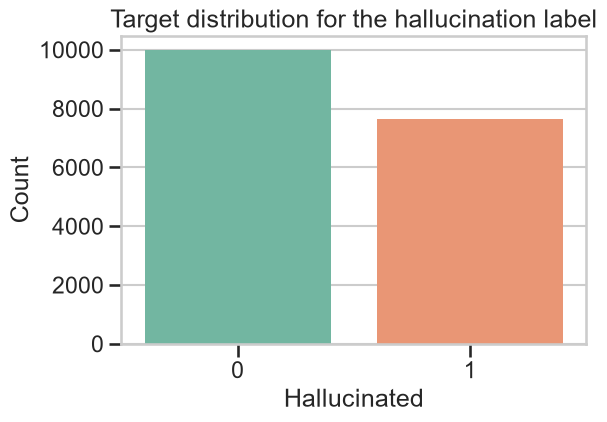

In [2]:
target_counts = df['hallucinated'].value_counts().sort_index()
print('Target counts:')
print(target_counts.to_string())
print('\nTarget proportions:')
print((target_counts / target_counts.sum() * 100).round(2).to_string())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='hallucinated', palette='Set2')
plt.title('Target distribution for the hallucination label')
plt.xlabel('Hallucinated')
plt.ylabel('Count')
plt.show()

In [3]:
# Critical leakage audit: the same source should not appear in both train and test.
from sklearn.model_selection import train_test_split

train_sources = df.loc[df['split'] == 'train', 'source_id']
test_sources = df.loc[df['split'] == 'test', 'source_id']
overlap = sorted(set(train_sources) & set(test_sources))

print('Train rows:', len(df[df['split'] == 'train']))
print('Test rows:', len(df[df['split'] == 'test']))
print('Overlapping source IDs:', len(overlap))
if overlap:
    print('Examples:', overlap[:10])
    leaked_rows = df[df['source_id'].isin(overlap)]
    print('Leaked rows:', len(leaked_rows))
    print('Leaked row counts by split:')
    print(leaked_rows['split'].value_counts().to_string())
else:
    print('No source_id overlap between train and test. The current split is leakage-safe.')

# If leakage exists, build a source-level split so the same source never appears in both sets.
if overlap:
    source_df = df[['source_id', 'hallucinated']].drop_duplicates().copy()
    source_labels = source_df.groupby('source_id')['hallucinated'].first().reindex(source_df['source_id'].unique()).to_numpy()
    unique_sources = source_df['source_id'].unique()
    train_sources_safe, test_sources_safe = train_test_split(
        unique_sources,
        test_size=0.2,
        stratify=source_labels,
        random_state=42,
    )
    df['safe_split'] = np.where(df['source_id'].isin(train_sources_safe), 'train', 'test')
    print('\nSafe split counts:')
    print(df['safe_split'].value_counts().to_string())
    print('Overlap after source-safe split:', len(set(df.loc[df['safe_split'] == 'train', 'source_id']) & set(df.loc[df['safe_split'] == 'test', 'source_id'])))
else:
    df['safe_split'] = df['split']
    print('\nUsing the existing split as the safe split.')

# Keep a clean view for downstream modeling.
print('\nFirst rows of the safe split column:')
print(df[['source_id', 'split', 'safe_split', 'hallucinated']].head(10).to_string(index=False))


Train rows: 14942
Test rows: 2675
Overlapping source IDs: 0
No source_id overlap between train and test. The current split is leakage-safe.

Using the existing split as the safe split.

First rows of the safe split column:
 source_id split safe_split  hallucinated
     15592 train      train             0
     15592 train      train             0
     15592 train      train             1
     15592 train      train             1
     15592 train      train             0
     15592 train      train             1
     15593 train      train             0
     15593 train      train             0
     15593 train      train             0
     15593 train      train             0
